In [1]:
from schedule import Schedule, Slot
from tsn_scheduling_problem import TSNScheduling
from usecase_generator import Usecase
from evaluator import TSNConstraintEvaluator
from tsn_scheduling_problem import TSNScheduling
from env_candidates import TSNCandidateHopEnv

In [2]:
problem = TSNScheduling("uc_config.cfg")

In [6]:
instance = problem.import_scheduling_usecase("simpleeee_scenario.json")

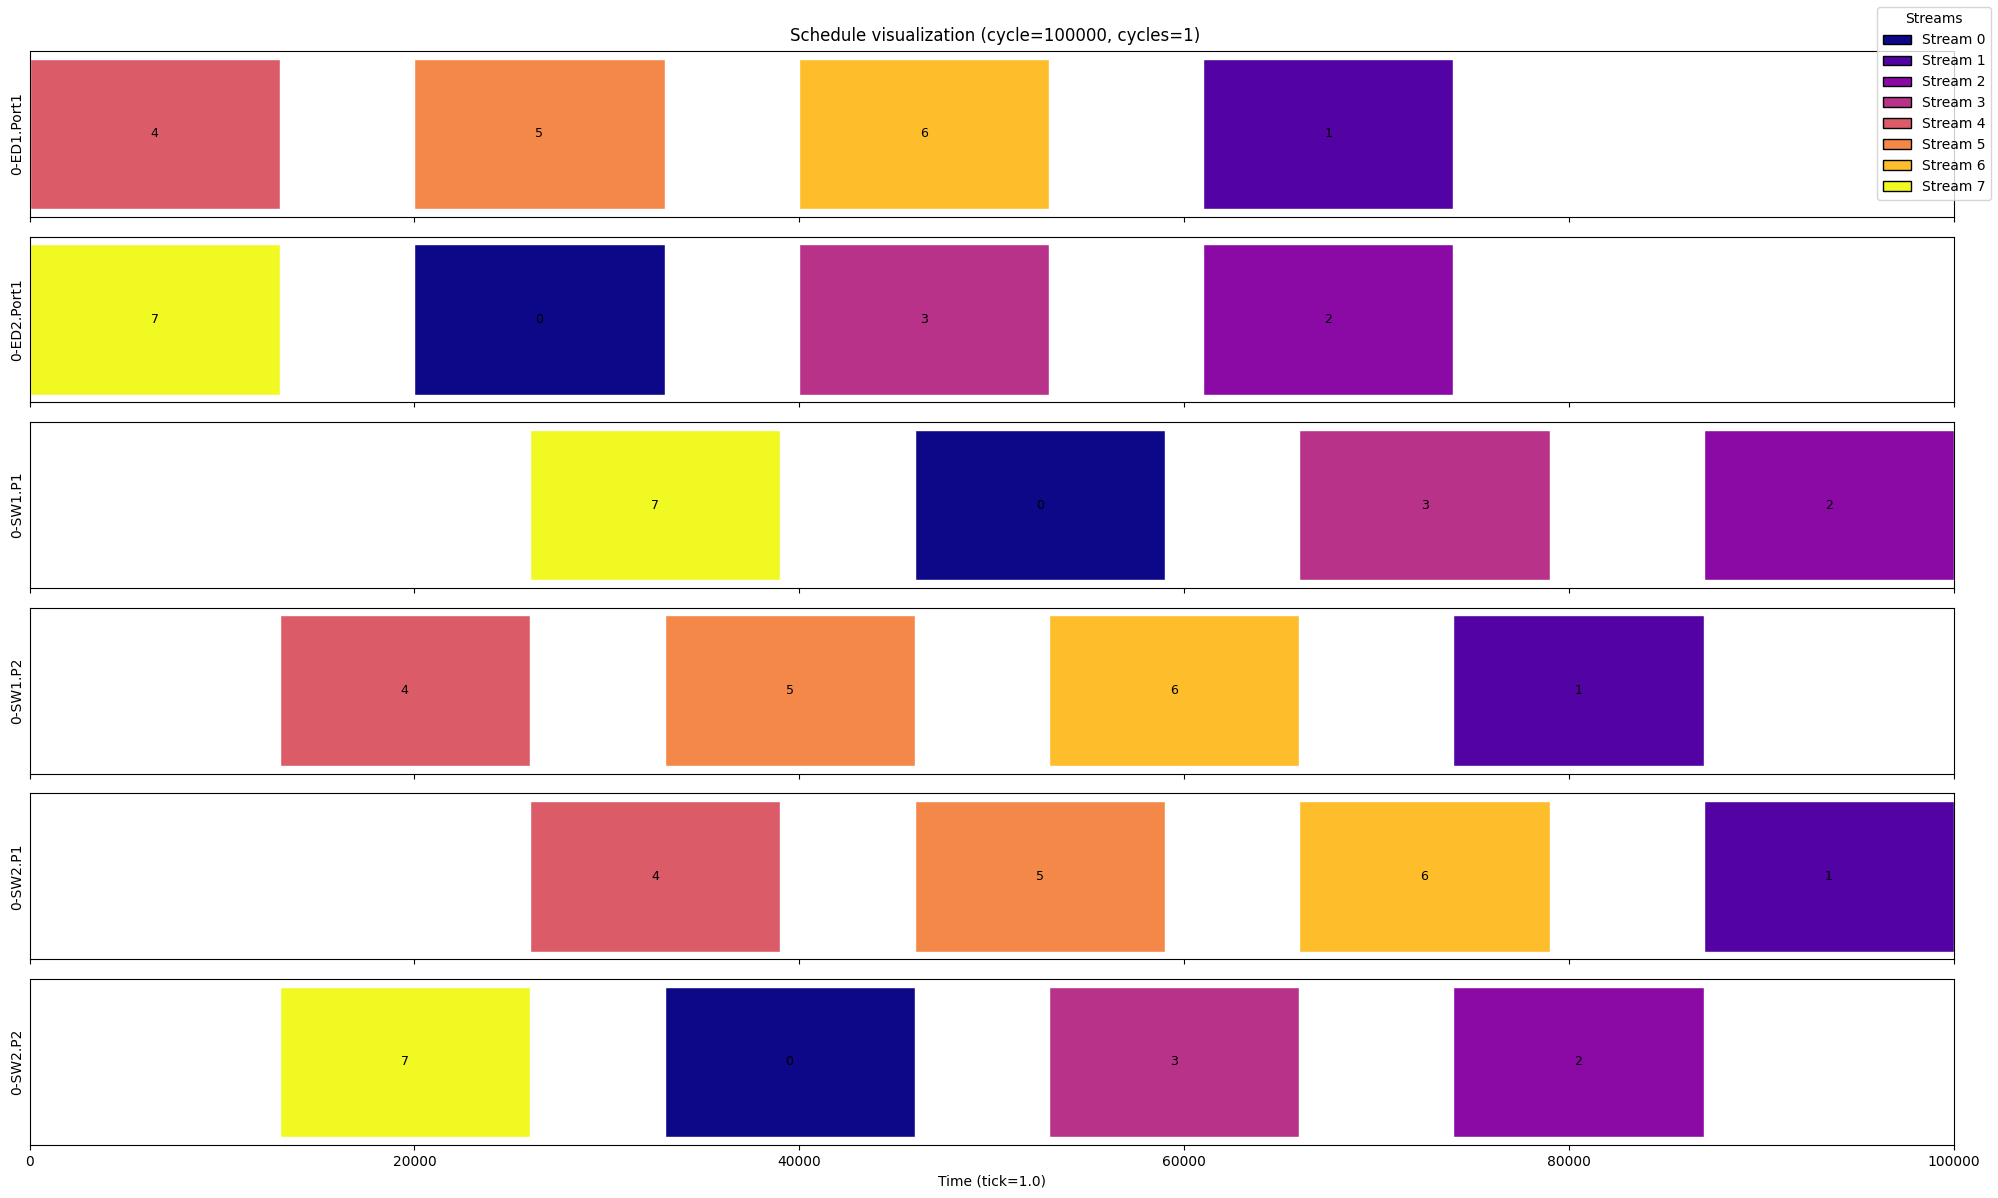

(<Figure size 2000x1200 with 6 Axes>,
 array([<Axes: ylabel='0-ED1.Port1'>, <Axes: ylabel='0-ED2.Port1'>,
        <Axes: ylabel='0-SW1.P1'>, <Axes: ylabel='0-SW1.P2'>,
        <Axes: ylabel='0-SW2.P1'>,
        <Axes: xlabel='Time (tick=1.0)', ylabel='0-SW2.P2'>], dtype=object))

In [7]:
instance.schedule.plot(cycles=1, label=True)

In [16]:
    
with problem.use_instance(instance):
    evaluator = TSNConstraintEvaluator(problem, check_routing=False, check_task_placement=False)
    compact = instance.schedule.to_compact_encoding(problem.n_ports, problem.n_streams)
    print(evaluator.per_stream_all_violations(compact))

[[0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0]]


In [1]:
from env2 import TSNDefragStepEnv
from env_candidates import TSNCandidateHopEnv
from tsn_scheduling_problem import TSNScheduling

problem = TSNScheduling("uc_config.cfg")
instance = problem.import_scheduling_usecase("simpleeee_scenario.json")

env2 = TSNDefragStepEnv(
    problem=problem,
    usecase=instance,
    expected_incoming_bytes=1024,
    acceptance_weight=2,
    reset_mode="never",
    init_from_usecase_schedule=True,
    max_steps=48,
)

cand = TSNCandidateHopEnv(
    problem=problem,
    usecase=instance,
    expected_incoming_bytes=1024,
    acceptance_weight=2,
    init_from_usecase_schedule=True,
    max_steps=48,
    max_candidates=10,
)

obs, _ = env2.reset()
print("env2 acceptance:", env2._global_metrics()["acceptance_count"])

obs, _ = cand.reset()
print("cand acceptance:", cand._global_metrics()["acceptance_count"])

env2 acceptance: 16.0
cand acceptance: 12.0
